# A Lightweight AI-Based Phishing Detection System Using Browser Behavior Analysis

**Goal:** test whether adding page-consistency and browser-behavior features improves phishing detection compared with URL-only features.

**Dataset:** PhiUSIIL Phishing URL Dataset (UCI), 235,795 URLs before cleaning.

**Approach:**
1. Baseline model: URL features only (19 features)
2. Hybrid model: URL + page consistency + browser behavior (37 features)
3. Compare Logistic Regression, Decision Tree, Random Forest and XGBoost

In [10]:
#load the data
import pandas as pd

df = pd.read_csv("../data/phiusiil_clean.csv")
print("Rows after cleaning:", df.shape[0])
print("Columns:", df.shape[1])
print()
print(df["label"].map({0: "Phishing", 1: "Legitimate"}).value_counts())

Rows after cleaning: 235370
Columns: 56

label
Legitimate    134850
Phishing      100520
Name: count, dtype: int64


## Model comparison: baseline vs hybrid

All models were trained on an 80/20 stratified split (47,074 test URLs). Phishing is the positive class.

In [11]:
#results table
res = pd.read_csv("../results/model_results.csv")
res.round(4)

,Feature set,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s),Predict time (s)
0,Baseline (URL only),Logistic Regression,0.9963,0.9993,0.9921,0.9957,0.9984,0.4500,0.0100
1,Baseline (URL only),Decision Tree,0.9970,0.9985,0.9946,0.9965,0.9958,0.4007,0.0101
2,Baseline (URL only),Random Forest,0.9974,0.9989,0.9950,0.9969,0.9983,1.8505,0.1430
3,Baseline (URL only),XGBoost,0.9976,0.9996,0.9948,0.9972,0.9988,0.9815,0.0252
4,Hybrid (URL + behavior),Logistic Regression,0.9991,0.9997,0.9982,0.9989,1.0000,0.6641,0.0201
5,Hybrid (URL + behavior),Decision Tree,0.9987,0.9983,0.9986,0.9984,0.9986,1.3780,0.0168
6,Hybrid (URL + behavior),Random Forest,0.9996,0.9996,0.9995,0.9995,1.0000,2.5961,0.0922
7,Hybrid (URL + behavior),XGBoost,0.9996,0.9996,0.9994,0.9995,1.0000,1.2823,0.0285


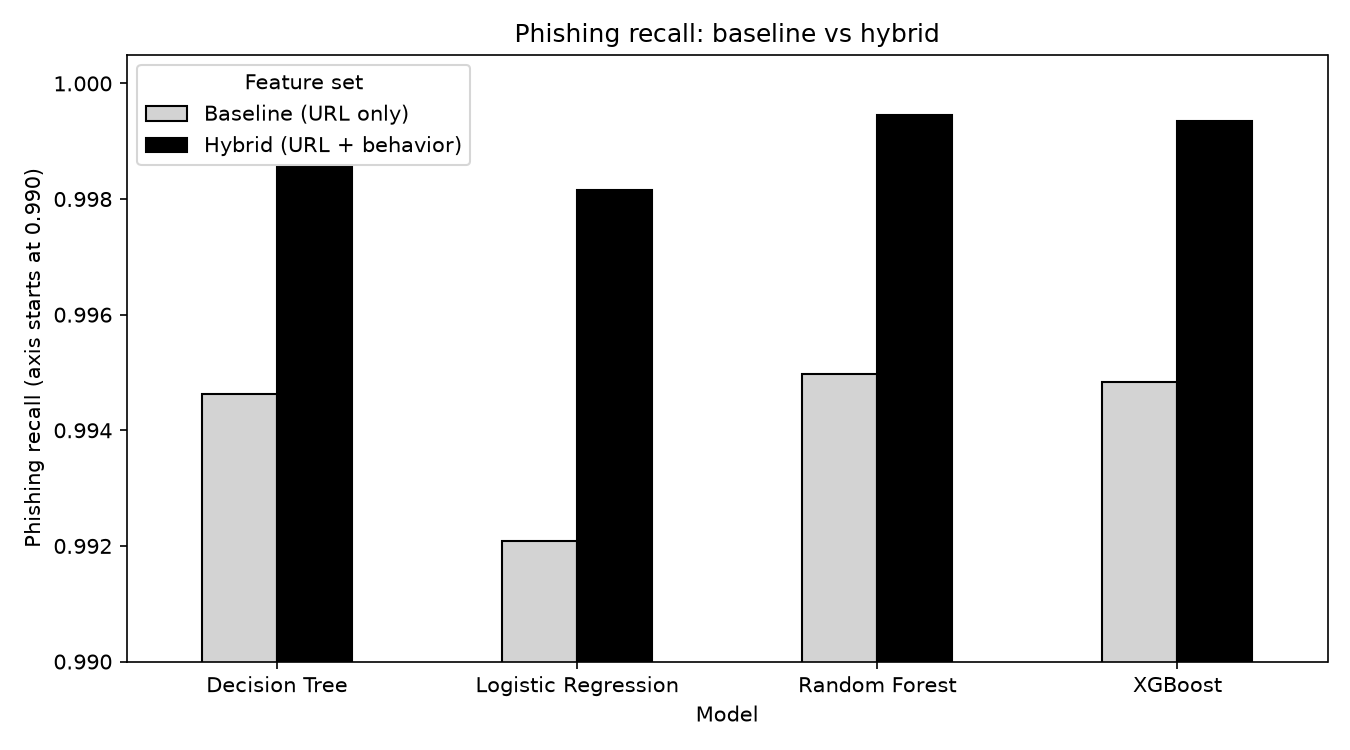

In [12]:
#recall chart
from IPython.display import Image
Image("../results/recall_comparison.png")

## Ablation: which feature group helps?

XGBoost was trained on four feature sets to find which group is responsible for the improvement.

In [13]:
#ablation table
abl = pd.read_csv("../results/ablation_results.csv")
abl.round(4)

,Feature set,Features,Accuracy,Precision,Recall,F1,Missed phishing (FN),False alarms (FP)
0,URL only,19,0.9976,0.9996,0.9948,0.9972,104,9
1,URL + consistency,29,0.9995,0.9996,0.9993,0.9995,14,8
2,URL + behavior,27,0.9975,0.9994,0.9947,0.9970,106,13
3,URL + consistency + behavior,37,0.9996,0.9996,0.9994,0.9995,13,8


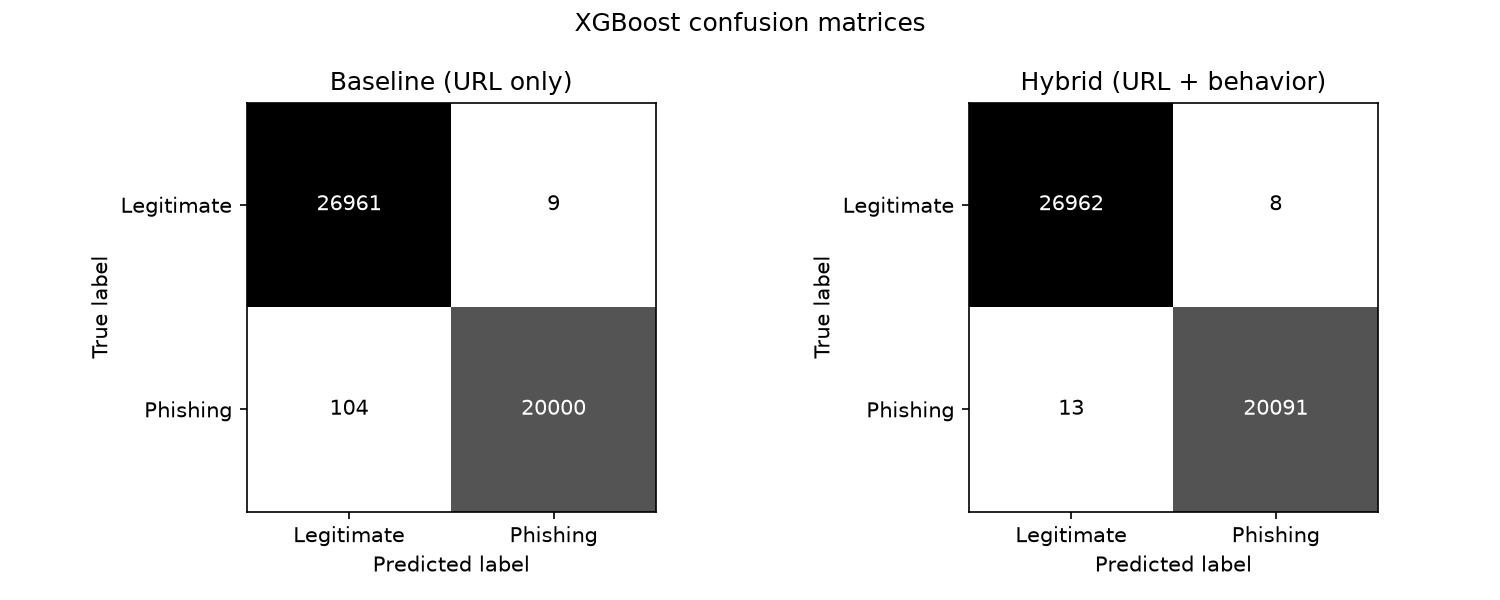

In [ ]:
Image("../results/confusion_matrix.png")

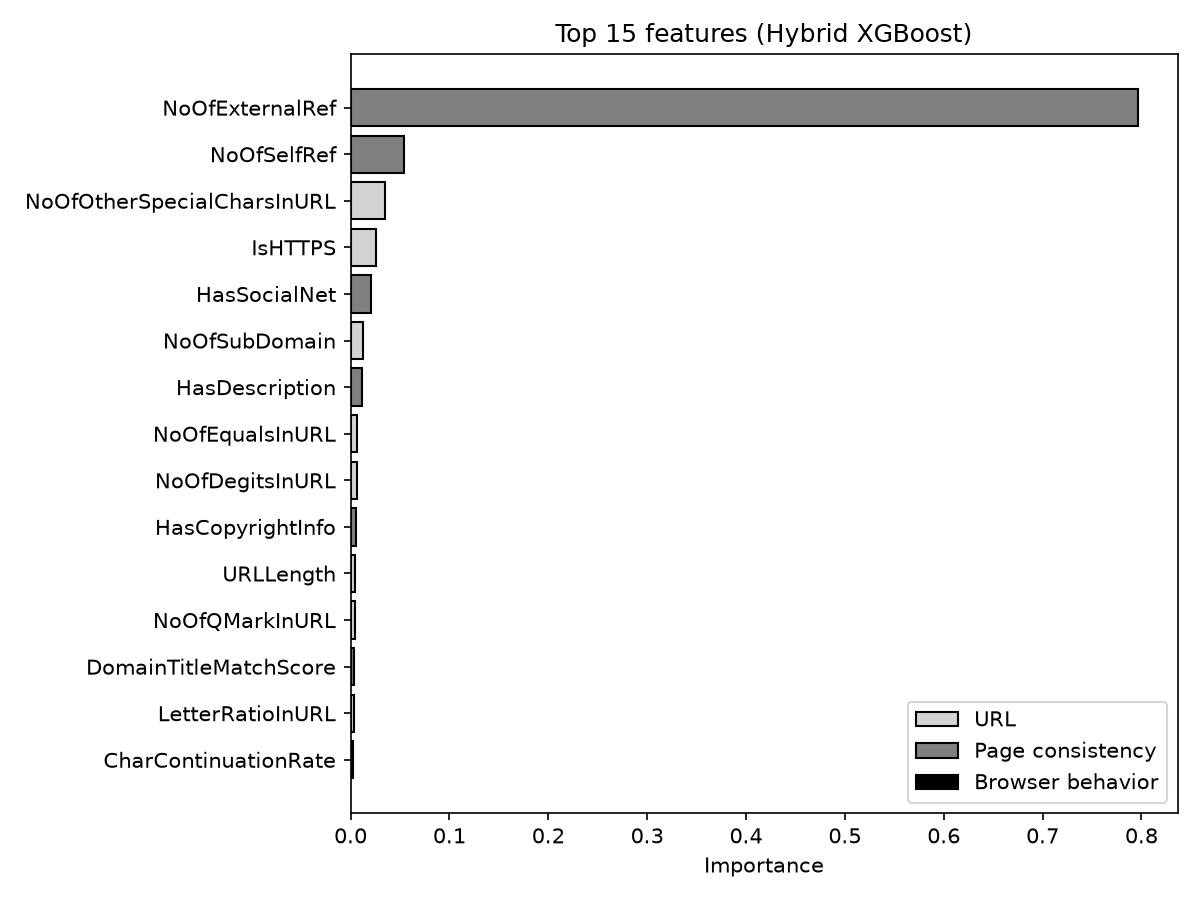

In [ ]:
Image("../results/feature_importance.png")

## Conclusion

- Adding page-consistency and browser-related features to URL features improved phishing detection for all four models.
- With XGBoost, missed phishing URLs dropped from 104 (URL only) to 13 (all features) on a test set of about 20,100 phishing URLs. Phishing recall rose from 0.9948 to 0.9994.
- The ablation shows that the page-consistency features (for example, the number of external references) account for almost all of this gain. The browser-behavior features alone (redirects, popups, iframes, form fields) gave no improvement over URL-only features, and added only one extra catch on top of the consistency features.
- The models are lightweight: each trains in about 1 to 3 seconds and predicts on 47,074 URLs in under 0.15 seconds.

## Limitations and future scope

**Limitations**
- The "browser behavior" columns in PhiUSIIL (redirects, popups, iframes, hidden fields) are extracted from the page's static HTML, not recorded from a live browser session.
- Results are very high even for the URL-only baseline (about 99.7% accuracy), so the room for improvement on this dataset is small.
- The dataset is a single snapshot. Phishing pages change quickly, so the models would need regular retraining.
- Three dataset columns (URLSimilarityIndex, TLDLegitimateProb, URLCharProb) were left out because they are computed from other URLs in the dataset and could inflate results.

**Future scope**
- A Selenium module that records real browser behavior (redirect chains, popups, form actions) for a sample of URLs.
- A browser extension that warns users in real time.
- Testing on a second, independent dataset to check that the results hold.
- Multilingual phishing detection.